In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import pdb
import os
from netCDF4 import Dataset
import cartopy.io.shapereader as shpreader
import cartopy.crs as ccrs
from cartopy.feature import ShapelyFeature
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pylab import *
from shapely.geometry.polygon import LinearRing

In [2]:
def get_coord(df,cities):
    '''Here we get the coordinates for each of the cities we want depending on the pollutants we need'''
    city_coord = {'Ciudad':[],'Lat':[],'Lon':[]}
    for city in cities.Ciudades.unique():
        city_coord['Ciudad'].append(city)
        city_coord['Lat'].append(df[df.CIUDAD == city].LATITUD.mean())
        city_coord['Lon'].append(df[df.CIUDAD == city].LONGITUD.mean())
    coords = pd.DataFrame.from_dict(city_coord)
    return(coords)

def time_means(df):
    '''Calculates all the means from a DF and takeout fliers or 0 and markers of missing values
    For ozone the daymean and everything else is calculated from the daily 8h max mean'''
    df.replace(0,np.nan, inplace=True)
    df.replace(9999.,np.nan, inplace=True)
    hourmean = df.groupby(df.index.hour).mean()
    hourstd = df.groupby(df.index.hour).std()
    if var == 'O3':
        df = df.resample('8h').mean().resample('d').max()
    monmean = df.groupby(df.index.month).mean()
    monstd = df.groupby(df.index.month).std()
    weekmean = df.groupby(df.index.weekday).mean()
    weekstd = df.groupby(df.index.weekday).std()
    return(monmean,weekmean,hourmean,monstd,weekstd,hourstd)

def transform_normal_coords(ds,year,var):
    tmp = ds[var].sel(XTIME=slice(f'{year}-01-01',f'{year}-12-31'))
    lat = np.linspace(tmp.XLAT.min(),tmp.XLAT.max(),len(tmp.XLAT))
    lon = np.linspace(tmp.XLONG.min(),tmp.XLONG.max(), len(tmp.XLONG))
    ds = xr.DataArray(tmp,dims=['time', 'latitude', 'longitude'],
                      coords=[tmp.XTIME.values,lat,lon])
    return(ds)

def extract_cams_vars_coord(ds, df, var, coord):
    columns = df[var].columns.values
    var_mat = np.ones((len(columns),len(ds)))*np.nan
    for i,city in enumerate(columns):
        test = ds.sel(longitude=[coord[coord.Ciudad == city]['Lon']], 
                      latitude=[coord[coord.Ciudad == city]['Lat']], method='nearest')
        var_mat[i,:] = np.array(test).flatten()
    data = pd.DataFrame(np.column_stack((var_mat)), columns = columns)
    return(data)  

# Domain plots

In [3]:
##Read the topography
path_top = '/nfs/scistore16/mullegrp/acasalla/MPI-C/'
np.bool = np.bool_
crs = ccrs.PlateCarree()
topo = f'{path_top}GMRTv3_6_20190709topo.grd'
vart = Dataset(topo, mode='r')
xtopo=np.arange(vart.variables['x_range'][0],vart.variables['x_range'][1]+0.5*vart.variables['spacing'][0],
                vart.variables['spacing'][0])
ytopo=np.arange(vart.variables['y_range'][0],vart.variables['y_range'][1]+0.5*vart.variables['spacing'][1],
                vart.variables['spacing'][1])
xt0,yt0=np.meshgrid(xtopo,ytopo)
z = vart.variables['z'][:]
z = np.reshape(z, xt0.shape)[::-1,:]

## Shapes
world = f'{path_top}World_Countries/World_Countries.shp'
col = f'{path_top}World_Countries/COL_no_dptos.shp'
dept = f'{path_top}World_Countries/GDBIDEAM_departamentos.shp'
muni = f'{path_top}World_Countries/mpio/mpio.shp'

In [4]:
#### This is to get the cities with data
path = '/nfs/scistore16/mullegrp/acasalla/MPI-C/'

cities = pd.DataFrame()
pollutants = ['PM25','O3']
tmp = np.array([])

for pollu in pollutants:
    df_tmp = pd.read_csv(f'{path}Datos_estaciones/Pollutant_trend_data/Hourmean/{pollu}_hourmean_Colombia.csv', 
                      parse_dates = True, index_col = 0)
    tmp = np.append(tmp,df_tmp.columns.values)

cities['Ciudades'] = tmp

#### Lets get the lat and lon of the cities with data
df_tmp = pd.read_csv(f'{path}Datos_estaciones/catalogo_estaciones_con_ciudades_Colombia.csv', encoding = 'latin-1')
coord = get_coord(df_tmp,cities)

In [6]:
markers = ['o','*','s','v','^','>','<','p','P','X','D','H','d']
linewidths = [0.1,0.15,0.3]#,0.4]
shps = [world,dept,col]
#modify matplotlib's 'terrain' colormap to make it better
import matplotlib.colors
colors_land = plt.cm.terrain(np.linspace(0.3, 1, 200))
colors=colors_land
terrain_map = matplotlib.colors.LinearSegmentedColormap.from_list('terrain_map', colors)


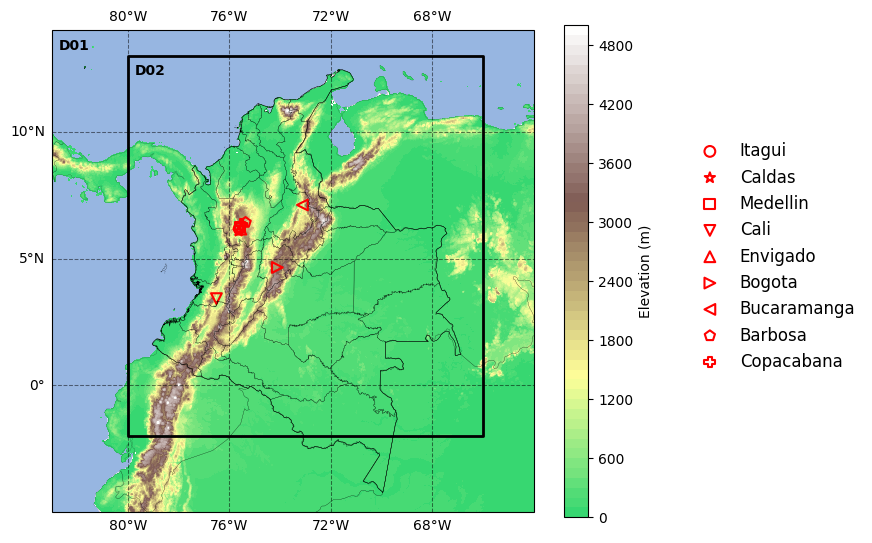

In [7]:
a_lat = [-2,-2,13,13]
a_lon = [-66,-80,-80,-66]
ring = LinearRing(list(zip(a_lon, a_lat)))

mc = ['k','purple','k','k','purple','k','purple','k','purple','red','red','red','red']
mc = ['red']*9

fig = plt.figure(figsize=(7,8))
gs = GridSpec(1,1,left = 0.09, right = 0.95, hspace=0.01, wspace=0.1, top = 0.9, bottom = 0.08)

ax = plt.subplot(gs[0], projection = crs)
curvas = plt.contourf(xt0, yt0, z, levels = np.arange(0,5006,100), cmap = terrain_map)
ax.set_extent([-83,-64,-5,14])
cbar = plt.colorbar(curvas, ax = ax, shrink = 0.75, orientation = 'vertical')
cbar.set_label('Elevation (m)')
ax.add_geometries([ring], ccrs.PlateCarree(), facecolor='none', edgecolor='k', linewidth=2)
gl = ax.gridlines(crs = crs, draw_labels = True, linewidth = 0.75, color='k', 
                      alpha = 0.5, linestyle = '--')
gl.xlocator = mticker.FixedLocator([-68,-72,-76,-80]) 
gl.ylocator = mticker.FixedLocator([-5,0,5,10])
gl.right_labels = False
ax.text(-82.75,13.25,'D01', fontweight = 'bold')
ax.text(-79.75,12.25,'D02', fontweight = 'bold')
ax.add_feature(cfeature.OCEAN)

for k,shp in enumerate(shps):
        shape_feature = ShapelyFeature(shpreader.Reader(shp).geometries(),crs, facecolor='none', 
                                       edgecolor = 'k', linewidth=linewidths[k])
        ax.add_feature(shape_feature)

for j,city in enumerate(coord.Ciudad.values[:-4]):
    plt.scatter(coord[coord.Ciudad == city].Lon.values, coord[coord.Ciudad == city].Lat.values,
                label = city, marker = markers[j], s = 60, edgecolor = mc[j], facecolors = "None", 
                linewidth = 1.5)
plt.legend(frameon=False, ncol = 1, bbox_to_anchor = (1.5,0.8), loc = 'upper center', fontsize = 12)
plt.savefig(f'{path}Figures/Domains_MPI-C_WRF.pdf', bbox_inches = 'tight', dpi = 300)
plt.savefig(f'{path}Figures/Domains_MPI-C_WRF.jpg', bbox_inches = 'tight', dpi = 300)

# Comparing WRF-Chem with the available stations

In [8]:
def errors(M,O, umbral):
    '''This code calculate 9 metrics to evaluate model performance.
    To use it, you only need to pass two arrays, one is the model and
    the other one contain the observations. Be careful with the null values
    and the type of data! It is also important to make a good selection for the
    threshold!, if not the results would not be correct'''
    from scipy import stats
    from sklearn.metrics import mean_squared_error
    M = np.nan_to_num(M,nan=np.nanmean(M))
    O = np.nan_to_num(O,nan=np.nanmean(O))
    #pdb.set_trace()
    M_RAYA = np.mean(M)
    O_RAYA = np.mean(O)
    nmb = (np.sum(M - O)/np.sum(O)) * 100
    rmse = np.sqrt(mean_squared_error(O,M))
    r2 = (np.sum((M - M_RAYA) * (O - O_RAYA))/np.sqrt(np.sum((M - M_RAYA)**2) * np.sum((O - O_RAYA)**2)))**2
    fac2 = len([i for i in  M/O  if 0.5 <= i and i <=2])/ len(M)
    fac2 = fac2*100
    ioa = 1 - (np.sum((M - O)**2))/np.sum((np.abs(M - O_RAYA) + np.abs(O - O_RAYA))**2) 
    mb = np.mean((M - O))
    rho = stats.spearmanr(M,O)
    
    na = len([i for i in np.arange(0,len(M),1) if O[i] < umbral and M[i] > umbral])
    nb = len([i for i in np.arange(0,len(M),1) if O[i] > umbral and M[i] > umbral])
    nc = len([i for i in np.arange(0,len(M),1) if O[i] < umbral and M[i] < umbral])
    nd = len([i for i in np.arange(0,len(M),1) if O[i] < umbral and M[i] < umbral]) 
    
    if nb + nd > 0:  
        hit = (nb/(nb + nd))*100
    else:
        hit = 0
    if na + nb > 0:
        far = (na/(na + nb))*100
    else:
        far = 0
    if na + nb + nc + nd > 0:
        poc = ((nb + nc)/(na + nb + nc + nd))*100
    else:
        poc = 0
    return(round(nmb,2),round(rmse,2),round(r2,2),round(fac2,2),round(ioa,2),
           round(mb,2),round(hit,2),round(far,2),round(poc,2))

### Monthly means for the pollutants are needed

In [9]:
stat_mon = {}
year = 2019

for var in pollutants:
    df_all = pd.read_csv(f'{path}Datos_estaciones/Pollutant_trend_data/Hourmean/{var}_hourmean_Colombia.csv', 
                     parse_dates=True, index_col=0)
    df_tmp = df_all.loc[f'{year}-01-01':f'{year}-12-31']
    stat_mon[var],_,_,_,_,_ = time_means(df_tmp)

/tmp/ipykernel_2412351/4141211834.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.replace(0,np.nan, inplace=True)
/tmp/ipykernel_2412351/4141211834.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.replace(9999.,np.nan, inplace=True)
/tmp/ipykernel_2412351/4141211834.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.replace(0,np.nan, inplace=True)
/tmp/ipykernel_2412351/4141211834.py:15: SettingWithCopyWarning: 
A v

### Produce the time series for the cities from the WRF-Chem model

In [10]:
files = ['PM2_5','Ozone']
names = ['PM25','O3']
varis = ['PM2_5_DRY','o3']
const = [1,1000]
dfs_wrf = {}
ds_wrf = {}
for i,var in enumerate(varis):
    ds_tmp = xr.open_dataset(f'{path}Results/TOTALS/{files[i]}_TOTALS_ymonmean.nc')
    ds_wrf[names[i]] = transform_normal_coords(ds_tmp,year,var)
    dfs_wrf[names[i]] = extract_cams_vars_coord(ds_wrf[names[i]], stat_mon, names[i], coord)*const[i]

/nfs/scistore16/mullegrp/acasalla/.local/lib/python3.11/site-packages/xarray/core/indexes.py:615: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  value = np.asarray(value, dtype=dtype)
/nfs/scistore16/mullegrp/acasalla/.local/lib/python3.11/site-packages/xarray/core/indexes.py:615: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  value = np.asarray(value, dtype=dtype)


In [11]:
errores = ['NMB','RMSE','R$^{2}$','FAC2','IOA','MB','HIT','FAR','POC']
threshold = [10,30]
dict_err = {}

for j,pollu in enumerate(names):
    columns = dfs_wrf[pollu].columns.values
    err_mat = np.ones((9,len(columns)))*np.nan
    for i,city in enumerate(columns):
        err_mat[:,i] = errors(dfs_wrf[pollu][city],stat_mon[pollu][city], threshold[j])
    df_err = pd.DataFrame(np.column_stack((err_mat)), columns = errores)
    df_err['Ciudad'] = columns
    dict_err[f'{pollu}_errors'] = df_err

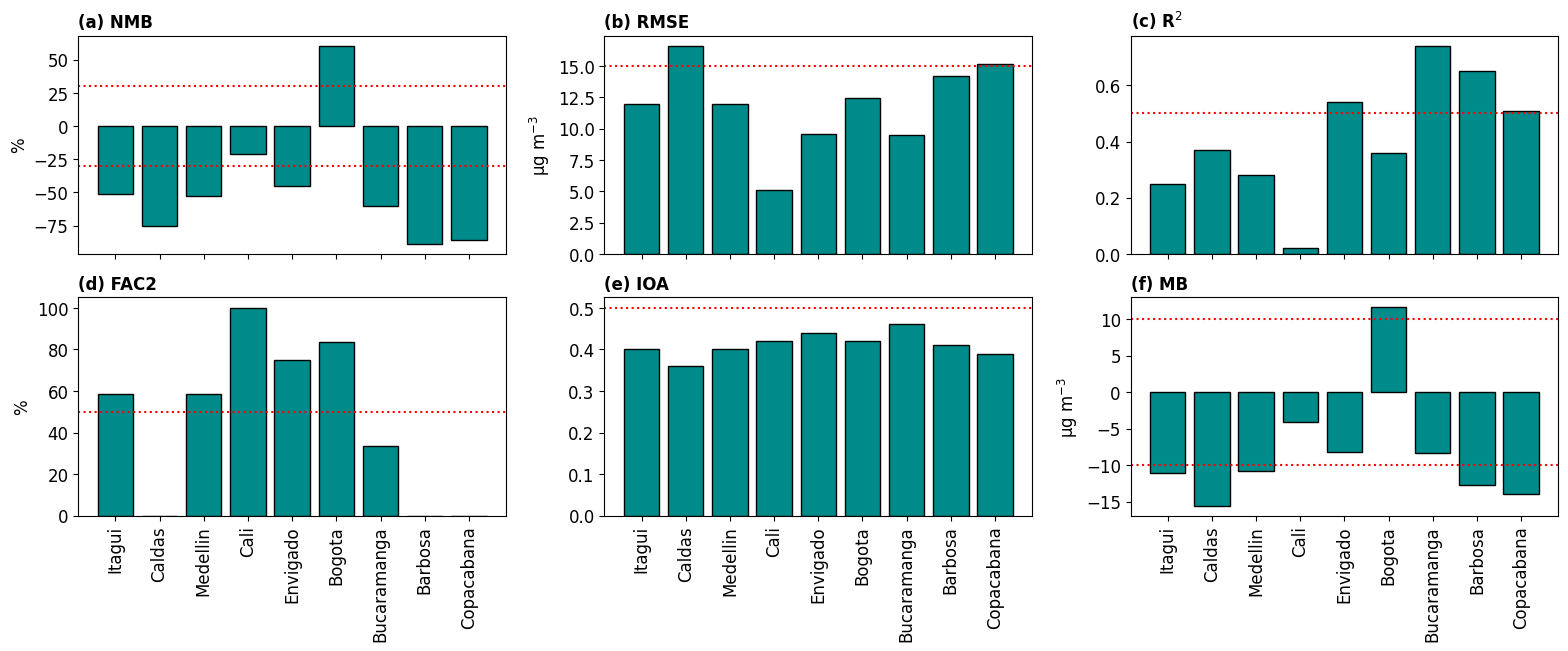

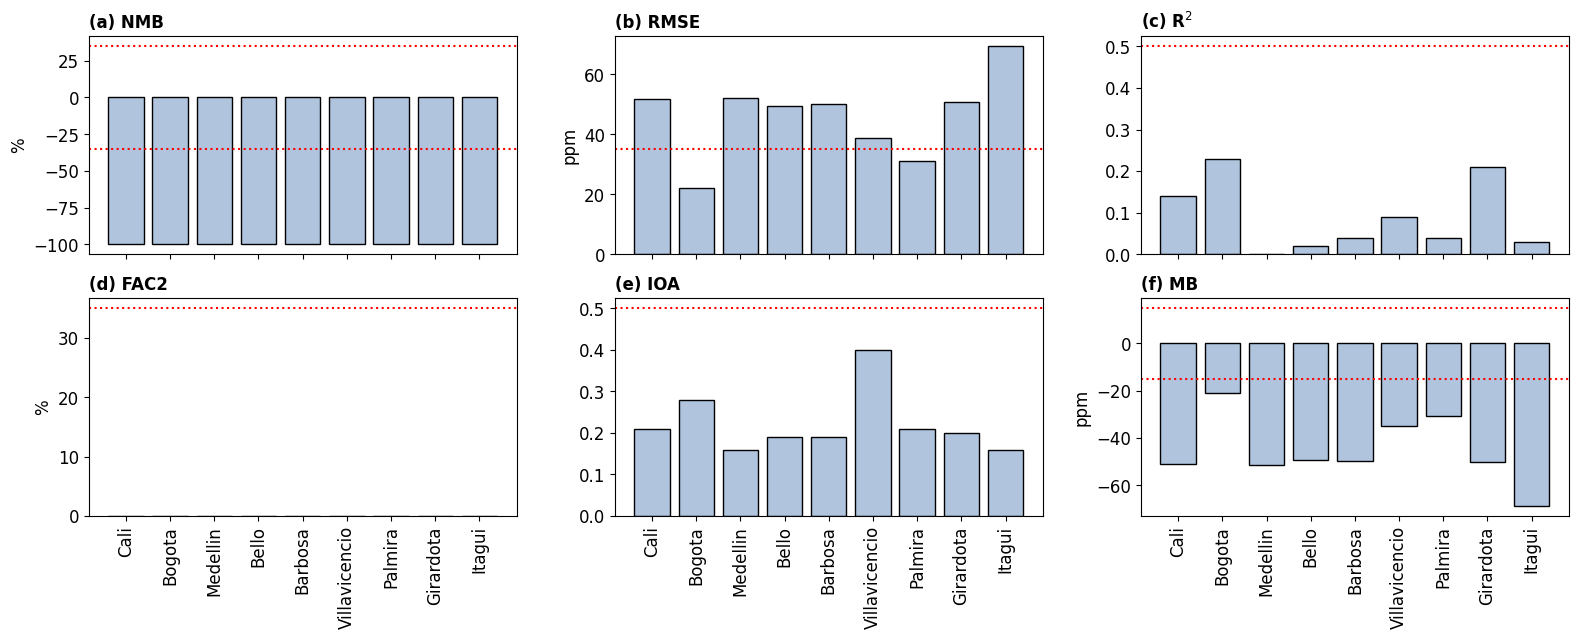

In [12]:
units = {'PM25':['%','\u03bcg m$^{-3}$','','%','','\u03bcg m$^{-3}$','%','%','%'],
         'O3':['%','ppm','','%','','ppm','%','%','%']}
title = ['(a)','(b)','(c)','(d)','(e)','(f)','(g)','(h)','(i)']
bench = {'PM25':[30, 15, 0.5, 50, 0.5, 10, 60, 40, 50], 
         'O3':[35, 35, 0.5, 35, 0.5, 15, 60, 40, 50]}

colors = ['darkcyan','lightsteelblue']


for j,pollu in enumerate(pollutants):
    fig = plt.figure(figsize=(16,6))
    gs = GridSpec(2,3, left=0.05, right=0.975, hspace=0.2, wspace=0.23, top=0.9, bottom=0.1)
    for i,error in enumerate(errores[0:6]):
        tmp = dict_err[f'{pollu}_errors']
        ax = subplot(gs[i])
        plt.bar(np.arange(1,len(tmp.Ciudad)+1),tmp[error], color = colors[j], edgecolor='k')
        plt.axhline(bench[pollu][i], color = 'red', linestyle = ':')
        if i == 0 or i == 5:
            plt.axhline(-bench[pollu][i], color = 'red', linestyle = ':')
        plt.title(f'{title[i]} {errores[i]}', loc = 'left', fontweight = 'bold')
        plt.ylabel(units[pollu][i], fontsize = 12)
        plt.xticks(np.arange(1,len(tmp.Ciudad)+1),tmp.Ciudad, fontsize = 12, rotation = 90)
        if i < 3:
            ax.xaxis.set_major_formatter(NullFormatter())
        plt.yticks(fontsize = 12)
    plt.savefig(f'{path}Figures/Errors_{pollu}_WRF_stations.pdf', bbox_inches = 'tight', dpi = 300)
    plt.show()

# Compare now WRF-Chem with Satellite from ACAG

In [13]:
def error_3D(M,O,time):
    '''This code calculate 6 metrics to evaluate model performance.
    To use it, you only need to pass two xarrays, one is the model and
    the other one contain the observations.'''
    M_RAYA = M.mean(dim=time)
    O_RAYA = O.mean(dim=time)
    nmb = ((M-O).sum(dim=time)/O.sum(dim=time)) * 100
    rmse = ((((M-O)**2).sum(dim=time)/len(O))**(1/2))
    a = ((M - M_RAYA) * (O - O_RAYA)).sum(dim=time)
    b = (((M - M_RAYA)**2).sum(dim=time)*((O - O_RAYA)**2).sum(dim=time))**(1/2)
    r2 = (a/b)**2
    fac2 = ((M/O).where((0.5 <= M/O) & (M/O <= 2)).count(dim=time)/len(M))
    fac2 = fac2*100
    ioa = 1 - ((M - O)**2).sum(dim=time)/((np.abs(M - O_RAYA) + np.abs(O - O_RAYA))**2).sum(dim=time)
    mb = (M - O).mean(dim=time)
    
    return(nmb,rmse,r2,fac2,ioa,mb)

In [14]:
### First regrid the ACAG files, and then merge them in the time dimension files
# V5 attrs GWRPM25 ----- V6 attrs PM25

version = '_V6' # '' for V5 and '_V6' for V6

if version == '_V6':
    varname = 'PM25'
else:
    varname = 'GWRPM25'

try:
    data = xr.open_dataset(f'{path}ACAG/PM25_NWSA_2019_regrid_all{version}.nc')
except:
    ### This takes quite some time the first time is run
    meses = np.arange(1,13)
    datasets = []
    for mes in meses:
        print(f'Running month: {mes:02}')
        inp = f'{path}ACAG/PM25_NWSA_2019{mes:02}{versiom}.nc'
        os.system(f'cdo remapcon,{path}ACAG/gridspec.txt {inp} {path}ACAG/PM25_NWSA_2019{mes:02}_regrid.nc')
        datasets.append(xr.open_dataset(f'{path}ACAG/PM25_NWSA_2019{mes:02}_regrid.nc'))
        os.system(f'rm {path}ACAG/PM25_NWSA_2019{mes:02}_regrid.nc')
    data = xr.concat(datasets, dim = 'time')
    data = data[varname].sel(lon=slice(-80,-66))
    data = data.where(data>0)
    data.to_netcdf(f'{path}ACAG/PM25_NWSA_2019_regrid_all{version}.nc')

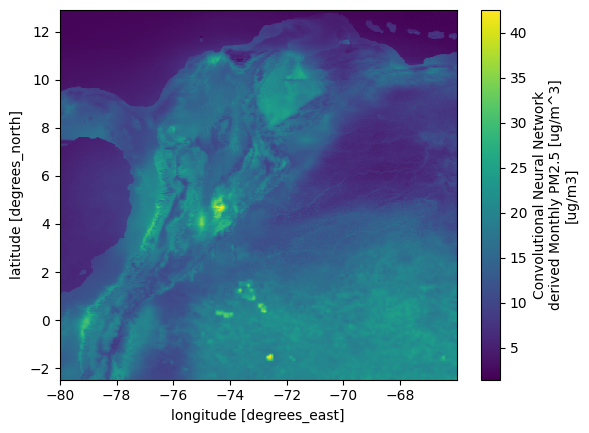

In [15]:
data.PM25[0,:,:].plot()

In [16]:
### WRF is a pain, since it does not have lonlat grid, so we need to convert it! and cut it, for ease
out = f'{path}Results/TOTALS/PM2_5_TOTALS_ymonmean_lonlat_grid.nc'

inp = f'{path}Results/TOTALS/PM2_5_TOTALS_ymonmean.nc'
#os.system(f'cdo -setgrid,{path}ACAG/gridspec.txt {inp} {out}')
ds = xr.open_dataset(f'{out}')
#os.system(f'rm {out}')
ds = ds.sel(lon=slice(-80,-66))
#ds.to_netcdf(f'{out}')

In [17]:
M = ds.PM2_5_DRY
M = M.rename({'XTIME':'time'})
O = data[varname]

xr_nmb,xr_rmse,xr_r2,xr_fac2,xr_ioa,xr_mb = error_3D(M,O,'time')

## It is time to plot

In [19]:
### Inputs for the map plot
tots = [xr_nmb,xr_rmse,xr_r2,xr_fac2,xr_ioa,xr_mb]
units = ['%','\u03bcg m$^{-3}$','','%','','\u03bcg m$^{-3}$','%','%','%']
levels = [np.arange(-20,20.1,2), np.arange(0,91,5), np.arange(0,1.01,0.1), 
          np.arange(0,100.1,5), np.arange(0,1.01,0.1), np.arange(-30,31,5)]
ticks = [np.arange(-20,20.1,5), np.arange(0,91,15), np.arange(0,1.01,0.2), 
          np.arange(0,100.1,10), np.arange(0,1.01,0.2), np.arange(-30,31,10)]
cmap = LinearSegmentedColormap.from_list('', ['lightblue','royalblue','orange','red'])
cmap_r = LinearSegmentedColormap.from_list('', ['red','orange','lightblue','royalblue','mediumblue'])
cmap_fac = LinearSegmentedColormap.from_list('', ['royalblue','lightblue','azure','orange','salmon',])
cmap_bi = LinearSegmentedColormap.from_list('', ['royalblue','lightblue','white','orange','red'])
colors = [cmap_bi, cmap, cmap, cmap_fac, cmap_bi, cmap_bi]
crs = ccrs.PlateCarree()
location = [0,1,2]*2
expand = ['both','max','neither','neither','neither','both']
markers = ['o','*','s','v','^','>','<','p','P','X','D','H','d']
linewidths = [0.1,0.15,0.3]#,0.4]
shps = [world,dept,col]
errores = ['NMB','RMSE','R$^{2}$','FAC2','IOA','MB','HIT','FAR','POC']

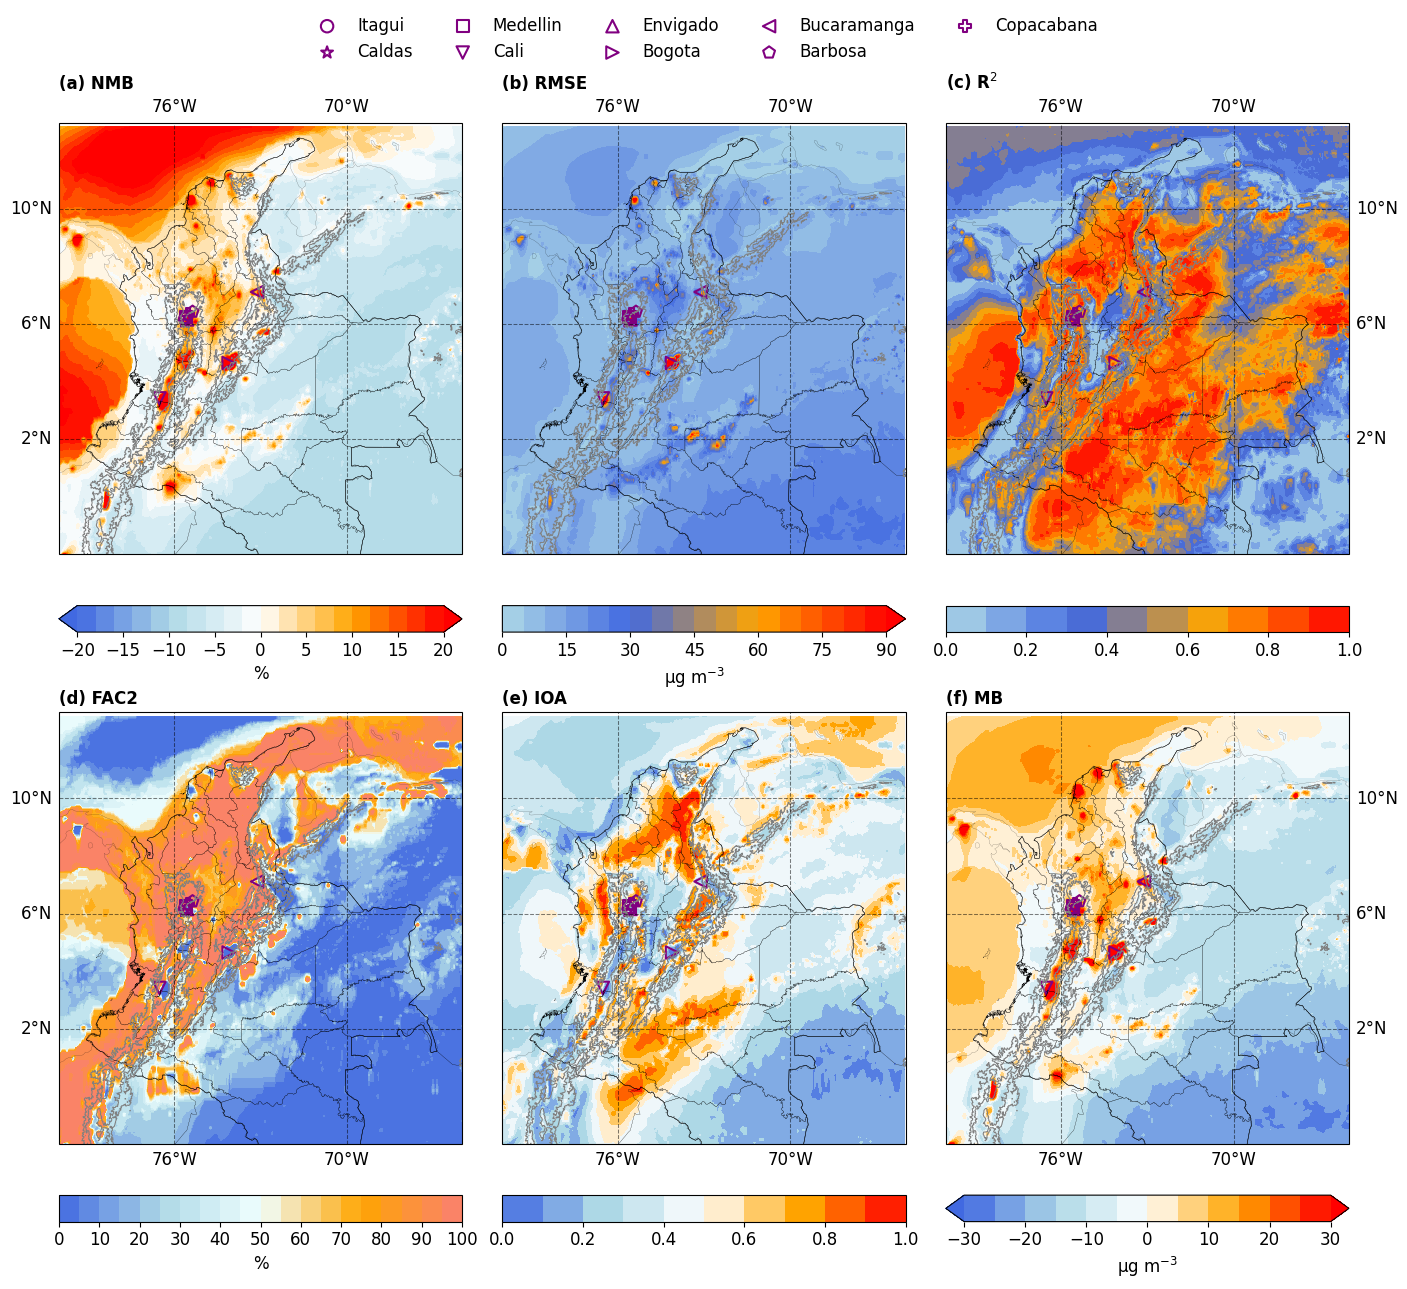

In [20]:
fig = plt.figure(figsize=(15,14))
gs = GridSpec(5,3,left = 0.09, right = 0.95, hspace=0.01, wspace=0.1, top = 0.9, bottom = 0.08, 
              height_ratios = [1,0.05,0.05,1,0.05])

mc = ['k','purple','k','k','purple','k','purple','k','purple','darkred','darkred','darkred','darkred']
mc = ['purple']*9


for i,tot in enumerate(tots):
    if i < 3:
        ax = plt.subplot(gs[0,location[i]], projection = crs)
    else:
        ax = plt.subplot(gs[3,location[i]], projection = crs)
    im = plt.contourf(tot['lon'], tot['lat'], tot.where(xr_rmse!=0), transform = crs, levels = levels[i],
                      cmap = colors[i], extend = expand[i])
    curvas = plt.contour(xt0, yt0, z, levels = np.arange(1500,3001,1500),colors = 'grey', 
                         linewidths = 0.75)
    
    for k,shp in enumerate(shps):
        shape_feature = ShapelyFeature(shpreader.Reader(shp).geometries(),crs, facecolor='none', 
                                       edgecolor = 'k', linewidth=linewidths[k])
        ax.add_feature(shape_feature)
    
    ax.set_extent([-66,-80,-2,13])
    plt.title(f'{title[i]} {errores[i]}', loc = 'left', fontweight = 'bold', fontsize = 12)
    for j,city in enumerate(coord.Ciudad.values[:-4]):
        plt.scatter(coord[coord.Ciudad == city].Lon.values, coord[coord.Ciudad == city].Lat.values,
                    label = city, marker = markers[j], s = 80, edgecolor = mc[j], facecolors = "None", 
                    linewidth = 1.5)
    if i == 1:
        plt.legend(frameon=False, ncol = 5, bbox_to_anchor = (0.5,1.28), loc = 'upper center', fontsize = 12)
    
    gl = ax.gridlines(crs = crs, draw_labels = True, linewidth = 0.75, color='k', 
                      alpha = 0.5, linestyle = '--')
    gl.xlocator = mticker.FixedLocator([-76, -70]) 
    gl.ylocator = mticker.FixedLocator([2, 6, 10])
    gl.xlabel_style = {'size': 12}; gl.ylabel_style = {'size': 12}
    if i == 0:
        gl.right_labels = False; gl.bottom_labels = False
    elif i == 1:
        gl.right_labels = False; gl.bottom_labels = False;  gl.left_labels = False
    elif i == 2:
        gl.left_labels = False; gl.bottom_labels = False
    elif i == 3:
        gl.right_labels = False; gl.top_labels = False
    elif i == 4:
        gl.right_labels = False; gl.top_labels = False; gl.left_labels = False
    elif i == 5:
        gl.left_labels = False; gl.top_labels = False

    #### Colorbar
    if i < 3:
        cax = plt.subplot(gs[1,location[i]])
    else:
        cax = plt.subplot(gs[4,location[i]])
    bar = plt.colorbar(im, orientation='horizontal', cax = cax, shrink = 0.8, ticks = ticks[i])
    bar.set_label(units[i], fontsize = 12)
    bar.ax.tick_params(labelsize = 12)
plt.savefig(f'{path}Figures/Errors_PM25_WRF_ACAG{version}.pdf', bbox_inches = 'tight', dpi = 300)
plt.savefig(f'{path}Figures/Errors_PM25_WRF_ACAG{version}.jpg', bbox_inches = 'tight', dpi = 300)

# Lets do yearly means

OSDMA8 is calculated as the annual maximum of the six-month running mean of the monthly average daily maximum 8 h mixing ratio, including through March of the following year to contain the Southern Hemisphere summer. (doi: 10.1088/1748-9326/ac66f3, for example)

## Stations ready

In [21]:
def err_year(M,O):
    '''This code calculate 9 metrics to evaluate model performance.
    To use it, you only need to pass two arrays, one is the model and
    the other one contain the observations. Be careful with the null values
    and the type of data! It is also important to make a good selection for the
    threshold!, if not the results would not be correct'''
    from scipy import stats
    from sklearn.metrics import mean_squared_error
    M = np.nan_to_num(M,nan=np.nanmean(M))
    O = np.nan_to_num(O,nan=np.nanmean(O))
    nmb = ((M - O)/(O)) * 100
    rmse = np.sqrt((M-O)**2/1) # yearly
    mb = np.mean((M - O))
    return(mb,nmb,rmse)

In [22]:
ds_ozo = xr.open_dataset(f'{path}Results/TOTALS/Ozone_TOTALS_ymonmean.nc')
osdma = ds_ozo.o3.max(dim=['XTIME'])*1000 #units
osdma.to_netcdf(f'{path}Results/TOTALS/Ozone_TOTALS_OSMDA.nc')
ds_pm = xr.open_dataset(f'{path}Results/TOTALS/PM2_5_TOTALS_ymonmean.nc') 
pm_ymean = ds_pm.PM2_5_DRY.mean(dim='XTIME')
#pm_ymean.to_netcdf(f'{path}Results/TOTALS/PM2_5_TOTALS_ymean.nc')

In [23]:
err_tot_y = {}
errores = ['MB','NMB','RMSE']
pollutant = ['PM25','O3']

for pollu in pollutant:
    erro_year = {}
    columns = dfs_wrf[pollu].columns.values
    print(columns)
    err_mat = np.ones((3,len(columns)))*np.nan
    for i,city in enumerate(columns): 
        if pollu == 'PM25':
            M = dfs_wrf[pollu][city].mean()
            O = stat_mon[pollu][city].mean()
        elif pollu == 'O3':
            M = dfs_wrf[pollu][city].max()
            O = stat_mon[pollu][city].max()
        err_mat[:,i] = err_year(M,O)
    erro_year[pollu] = err_mat
    df = pd.DataFrame.from_dict(erro_year[pollu])
    df.columns = dfs_wrf[pollu].columns.values
    err_tot_y[pollu] = df

['Itagui' 'Caldas' 'Medellin' 'Cali' 'Envigado' 'Bogota' 'Bucaramanga'
 'Barbosa' 'Copacabana']
['Cali' 'Bogota' 'Medellin' 'Bello' 'Barbosa' 'Villavicencio' 'Palmira'
 'Girardota' 'Itagui']


## For the maps

In [24]:
def error_3D_year(M,O):
    '''This code calculate 6 metrics to evaluate model performance.
    To use it, you only need to pass two xarrays, one is the model and
    the other one contain the observations.'''
    nmb = ((M-O)/O) * 100
    rmse = (((M-O)**2)/1)**(1/2) #yearly
    mb = (M - O)
    return(mb,nmb,rmse)

In [25]:
M = ds.PM2_5_DRY
M = M.rename({'XTIME':'time'})
O = data[varname]

M_year = M.mean(dim='time')
O_year = O.mean(dim='time')
mb_y3D, nmb_y3D, rmse_y3D = error_3D_year(M_year,O_year)

## Plot

In [26]:
import seaborn as sns
import matplotlib.patches as mpatches

In [27]:
df_mb = pd.DataFrame(data = {'PM':err_tot_y['PM25'].loc[0],'O3':err_tot_y['O3'].loc[0]})
df_nmb = pd.DataFrame(data = {'PM':err_tot_y['PM25'].loc[1],'O3':err_tot_y['O3'].loc[1]})
df_rmse = pd.DataFrame(data = {'PM':err_tot_y['PM25'].loc[2],'O3':err_tot_y['O3'].loc[2]})

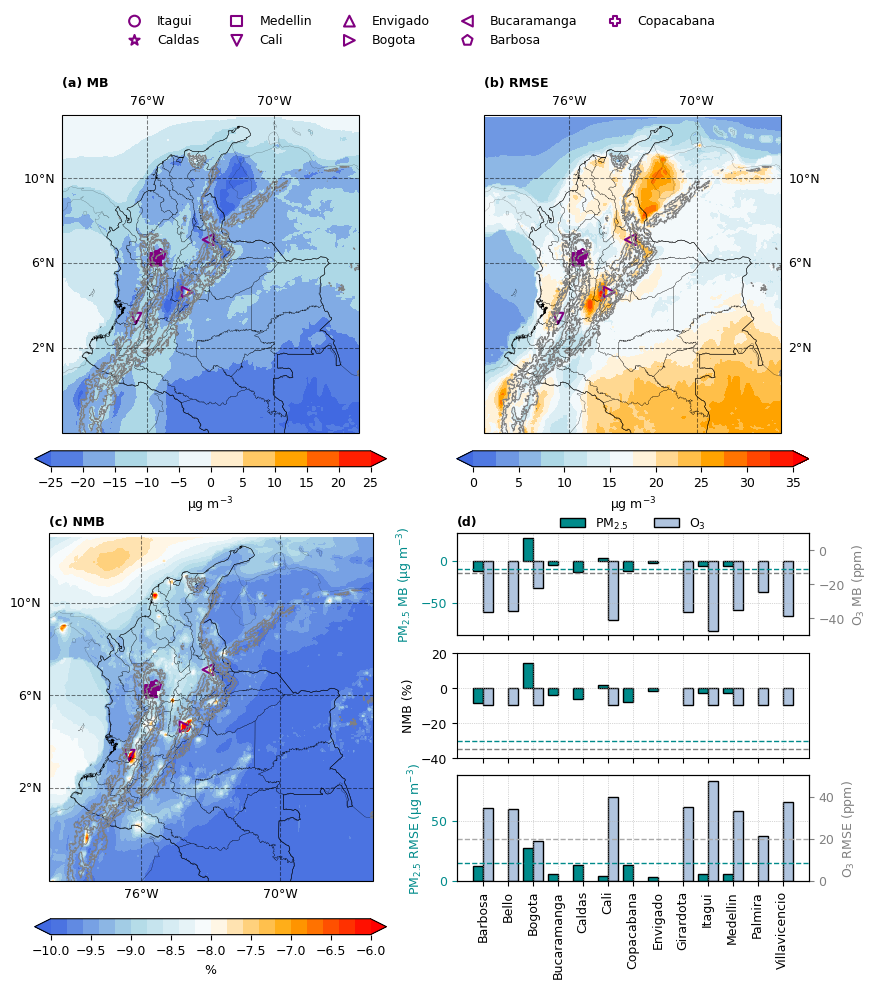

In [28]:
tots = [mb_y3D, rmse_y3D, nmb_y3D]
levels = [np.arange(-25,26,5), np.arange(0,35.01,2.5), np.arange(-10,-5.9,0.2)]
ticks = [np.arange(-25,26,5), np.arange(0,35.01,5), np.arange(-10,-5.9,0.5)]
colors = [cmap_bi, cmap_bi, cmap_bi]
units = ['\u03bcg m$^{-3}$','\u03bcg m$^{-3}$', '%']
crs = ccrs.PlateCarree()
location = [0,1,2]*2
expand = ['both','both','both']
my_colors = ['k','red','darkblue']
errores = ['MB','RMSE','NMB']

fig = plt.figure(figsize=(9,10))
gs = GridSpec(8,2,left = 0.09, right = 0.95, hspace=0.2, wspace=0.2, top = 0.9, bottom = 0.08, 
              height_ratios = [1,0.05,0.1,0.32,0.33,0.33,0.01,0.05])
for i,tot in enumerate(tots):
    if i < 2:
        ax = plt.subplot(gs[0,location[i]], projection = crs)
    else:
        ax = plt.subplot(gs[3:6,0], projection = crs)
    im = plt.contourf(tot['lon'], tot['lat'], tot.where(xr_rmse!=0), transform = crs, levels = levels[i],
                      cmap = colors[i], extend = expand[i])
    curvas = plt.contour(xt0, yt0, z, levels = np.arange(1500,3001,1500),colors = 'grey', 
                         linewidths = 0.75)
    
    for k,shp in enumerate(shps):
        shape_feature = ShapelyFeature(shpreader.Reader(shp).geometries(),crs, facecolor='none', 
                                       edgecolor = 'k', linewidth=linewidths[k])
        ax.add_feature(shape_feature)
    
    ax.set_extent([-66,-80,-2,13])
    plt.title(f'{title[i]} {errores[i]}', loc = 'left', fontweight = 'bold', fontsize = 9)
    for j,city in enumerate(coord.Ciudad.values[:-4]):
        plt.scatter(coord[coord.Ciudad == city].Lon.values, coord[coord.Ciudad == city].Lat.values,
                    label = city, marker = markers[j], s = 60, edgecolor = mc[j], facecolors = "None", 
                    linewidth = 1.5)
    if i == 0:
        plt.legend(frameon=False, ncol = 5, bbox_to_anchor = (1.2,1.35), loc = 'upper center', fontsize = 9)
    
    gl = ax.gridlines(crs = crs, draw_labels = True, linewidth = 0.75, color='k', 
                      alpha = 0.5, linestyle = '--')
    gl.xlocator = mticker.FixedLocator([-76, -70]) 
    gl.ylocator = mticker.FixedLocator([2, 6, 10])
    gl.xlabel_style = {'size': 9}; gl.ylabel_style = {'size': 9}
    if i == 0:
        gl.right_labels = False; gl.bottom_labels = False
    elif i == 1:
        gl.bottom_labels = False;  gl.left_labels = False
    elif i == 2:
        gl.right_labels = False; gl.top_labels = False
    #### Colorbar
    if i < 2:
        cax = plt.subplot(gs[1,location[i]])
    else:
        cax = plt.subplot(gs[7,0])
    bar = plt.colorbar(im, orientation='horizontal', cax = cax, shrink = 0.8, ticks = ticks[i])
    bar.set_label(units[i], fontsize = 9)
    bar.ax.tick_params(labelsize = 9)
    
ax = plt.subplot(gs[3,1])
plt.bar(np.arange(1,len(df_mb.index.values)+0.01)-0.2, df_mb.PM, width=0.4, 
        color='darkcyan', edgecolor = 'k', label = 'PM$_{2.5}$')
plt.bar(np.arange(1,len(df_mb.index.values)+0.01)+0.2, df_mb.O3, width=0.4, 
        color='lightsteelblue', edgecolor = 'k', label = 'O$_{3}$')
plt.xticks(np.arange(1,len(df_mb.index.values)+0.01),df_mb.index.values, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', linewidth = 0.5)
plt.ylabel('PM$_{2.5}$ MB (\u03bcg m$^{-3}$)', fontsize = 9, color = 'darkgrey')
ax.yaxis.label.set_color('darkcyan')
ax.tick_params(axis='y', colors = 'darkcyan')
plt.yticks(fontsize=9)
ax.xaxis.set_major_formatter(NullFormatter())
plt.title('(d)', fontweight = 'bold', fontsize = 9, loc = 'left')
plt.legend(frameon = False, bbox_to_anchor = (0.5,1.28), loc = 'upper center', fontsize = 9, ncol = 2)
plt.axhline(-10, color = 'darkcyan', linestyle = '--', linewidth = 1)
plt.axhline(-15, color = 'grey', linestyle = '--', linewidth = 1)
ax2 = ax.twinx()
plt.ylim(-50,10)
ax2.set_ylabel('O$_{3}$ MB (ppm)', color = 'grey', fontsize = 9)
plt.yticks(fontsize = 9)
ax2.yaxis.label.set_color('grey')
ax2.tick_params(axis='y', colors = 'grey')

ax = plt.subplot(gs[4,1])
plt.bar(np.arange(1,len(df_nmb.index.values)+0.01)-0.2, df_nmb.PM, width=0.4, 
        color='darkcyan', edgecolor = 'k')
plt.bar(np.arange(1,len(df_nmb.index.values)+0.01)+0.2, df_nmb.O3, width=0.4, 
        color='lightsteelblue', edgecolor = 'k')
plt.xticks(np.arange(1,len(df_nmb.index.values)+0.01),df_nmb.index.values, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', linewidth = 0.5)
plt.yticks(np.arange(-40,20.01, 20), fontsize = 9)
plt.ylim(-40,20)
plt.ylabel('NMB (%)', fontsize = 9)
ax.xaxis.set_major_formatter(NullFormatter())
plt.axhline(-30, color = 'darkcyan', linestyle = '--', linewidth = 1)
plt.axhline(-35, color = 'grey', linestyle = '--', linewidth = 1)

ax = plt.subplot(gs[5,1])
plt.bar(np.arange(1,len(df_rmse.index.values)+0.01)-0.2, df_rmse.PM, width=0.4, 
        color='darkcyan', edgecolor = 'k')
plt.bar(np.arange(1,len(df_rmse.index.values)+0.01)+0.2, df_rmse.O3, width=0.4, 
        color='lightsteelblue', edgecolor = 'k')
plt.xticks(np.arange(1,len(df_rmse.index.values)+0.01),df_rmse.index.values, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', linewidth = 0.5)
plt.yticks(fontsize = 9)
plt.ylabel('PM$_{2.5}$ RMSE (\u03bcg m$^{-3}$)', fontsize = 9)
plt.axhline(15, color = 'darkcyan', linestyle = '--', linewidth = 1)
plt.axhline(35, color = 'darkgrey', linestyle = '--', linewidth = 1)
ax.yaxis.label.set_color('darkcyan')
ax.tick_params(axis='y', colors = 'darkcyan')
ax2 = ax.twinx()
plt.ylim(0,50)
ax2.set_ylabel('O$_{3}$ RMSE (ppm)', color = 'grey', fontsize = 9)
plt.yticks(fontsize = 9)
ax2.yaxis.label.set_color('grey')
ax2.tick_params(axis='y', colors = 'grey')
plt.savefig(f'{path}Figures/Errors_yearly{version}.pdf', bbox_inches = 'tight', dpi = 300)
plt.savefig(f'{path}Figures/Errors_yearly{version}.jpg', bbox_inches = 'tight', dpi = 300)

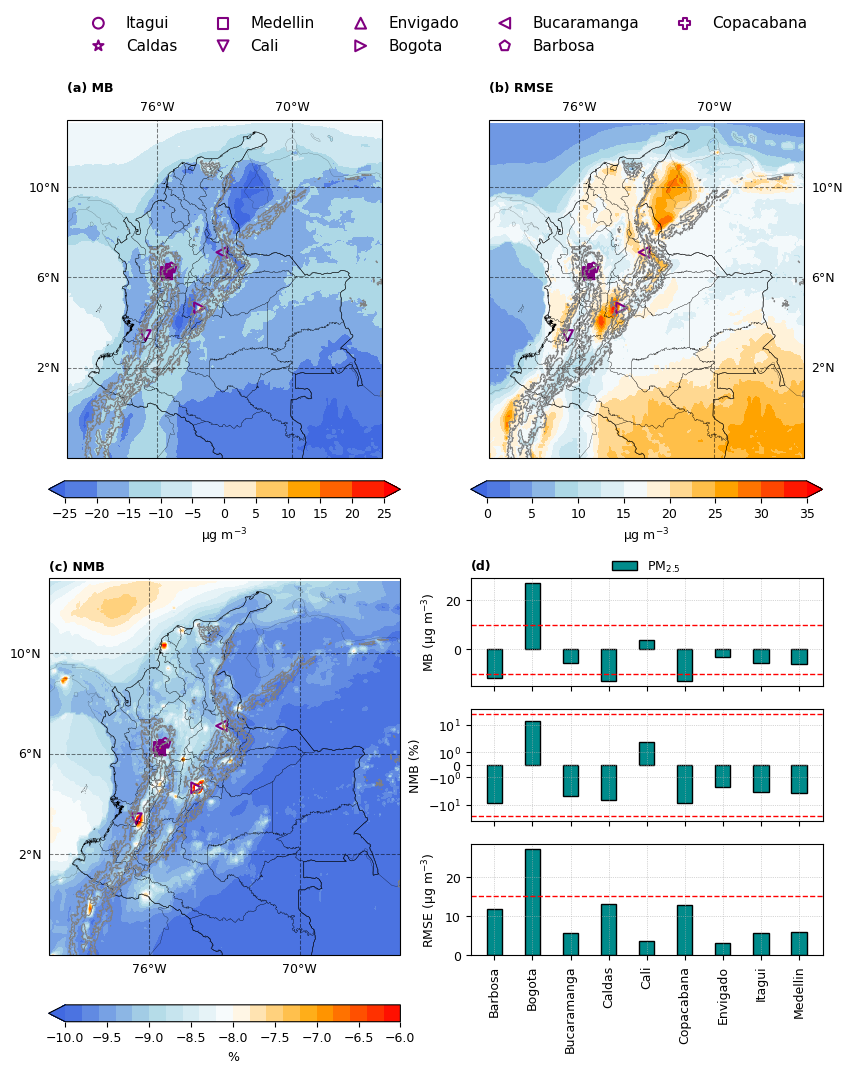

In [41]:
tots = [mb_y3D, rmse_y3D, nmb_y3D]
levels = [np.arange(-25,26,5), np.arange(0,35.01,2.5), np.arange(-10,-5.9,0.2)]
ticks = [np.arange(-25,26,5), np.arange(0,35.01,5), np.arange(-10,-5.9,0.5)]
colors = [cmap_bi, cmap_bi, cmap_bi]
units = ['\u03bcg m$^{-3}$','\u03bcg m$^{-3}$', '%']
crs = ccrs.PlateCarree()
location = [0,1,2]*2
expand = ['both','both','min']
my_colors = ['k','red','darkblue']
errores = ['MB','RMSE','NMB']

fig = plt.figure(figsize=(9,11))
gs = GridSpec(8,2,left = 0.09, right = 0.95, hspace=0.25, wspace=0.2, top = 0.9, bottom = 0.08, 
              height_ratios = [1,0.05,0.1,0.32,0.33,0.33,0.01,0.05])
for i,tot in enumerate(tots):
    if i < 2:
        ax = plt.subplot(gs[0,location[i]], projection = crs)
    else:
        ax = plt.subplot(gs[3:6,0], projection = crs)
    im = plt.contourf(tot['lon'], tot['lat'], tot.where(xr_rmse!=0), transform = crs, levels = levels[i],
                      cmap = colors[i], extend = expand[i])
    curvas = plt.contour(xt0, yt0, z, levels = np.arange(1500,3001,1500),colors = 'grey', 
                         linewidths = 0.75)
    
    for k,shp in enumerate(shps):
        shape_feature = ShapelyFeature(shpreader.Reader(shp).geometries(),crs, facecolor='none', 
                                       edgecolor = 'k', linewidth=linewidths[k])
        ax.add_feature(shape_feature)
    
    ax.set_extent([-66,-80,-2,13])
    plt.title(f'{title[i]} {errores[i]}', loc = 'left', fontweight = 'bold', fontsize = 9)
    for j,city in enumerate(coord.Ciudad.values[:-4]):
        plt.scatter(coord[coord.Ciudad == city].Lon.values, coord[coord.Ciudad == city].Lat.values,
                    label = city, marker = markers[j], s = 60, edgecolor = mc[j], facecolors = "None", 
                    linewidth = 1.5)
    if i == 0:
        plt.legend(frameon=False, ncol = 5, bbox_to_anchor = (1.2,1.35), loc = 'upper center', fontsize = 11)
    
    gl = ax.gridlines(crs = crs, draw_labels = True, linewidth = 0.75, color='k', 
                      alpha = 0.5, linestyle = '--')
    gl.xlocator = mticker.FixedLocator([-76, -70]) 
    gl.ylocator = mticker.FixedLocator([2, 6, 10])
    gl.xlabel_style = {'size': 9}; gl.ylabel_style = {'size': 9}
    if i == 0:
        gl.right_labels = False; gl.bottom_labels = False
    elif i == 1:
        gl.bottom_labels = False;  gl.left_labels = False
    elif i == 2:
        gl.right_labels = False; gl.top_labels = False
    #### Colorbar
    if i < 2:
        cax = plt.subplot(gs[1,location[i]])
    else:
        cax = plt.subplot(gs[7,0])
    bar = plt.colorbar(im, orientation='horizontal', cax = cax, shrink = 0.8, ticks = ticks[i])
    bar.set_label(units[i], fontsize = 9)
    bar.ax.tick_params(labelsize = 9)
    
ax = plt.subplot(gs[3,1])
pm_mb = df_mb.PM.dropna()
plt.bar(np.arange(1,len(pm_mb.index.values)+0.01), pm_mb, width=0.4, 
        color='darkcyan', edgecolor = 'k', label = 'PM$_{2.5}$')
#plt.bar(np.arange(1,len(df_mb.index.values)+0.01)+0.2, df_mb.O3, width=0.4, 
#        color='lightsteelblue', edgecolor = 'k', label = 'O$_{3}$')
plt.xticks(np.arange(1,len(pm_mb.index.values)+0.01),pm_mb.index.values, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', linewidth = 0.5)
plt.ylabel('MB (\u03bcg m$^{-3}$)', fontsize = 9, color = 'darkgrey')
ax.yaxis.label.set_color('k')
#ax.tick_params(axis='y', colors = 'darkcyan')
plt.yticks(fontsize=9)
ax.xaxis.set_major_formatter(NullFormatter())
plt.title('(d)', fontweight = 'bold', fontsize = 9, loc = 'left')
plt.legend(frameon = False, bbox_to_anchor = (0.5,1.28), loc = 'upper center', fontsize = 9, ncol = 2)
plt.axhline(-10, color = 'red', linestyle = '--', linewidth = 1)
plt.axhline(10, color = 'red', linestyle = '--', linewidth = 1)
#plt.axhline(-15, color = 'grey', linestyle = '--', linewidth = 1)
#ax2 = ax.twinx()
#plt.ylim(-50,10)
#ax2.set_ylabel('O$_{3}$ MB (ppm)', color = 'grey', fontsize = 9)
plt.yticks(fontsize = 9)
#ax2.yaxis.label.set_color('grey')
#ax2.tick_params(axis='y', colors = 'grey')

ax = plt.subplot(gs[4,1])
pm_nmb = df_nmb.PM.dropna()
plt.bar(np.arange(1,len(pm_nmb.index.values)+0.01), pm_nmb, width=0.4, 
        color='darkcyan', edgecolor = 'k')
#plt.bar(np.arange(1,len(df_nmb.index.values)+0.01)+0.2, df_nmb.O3, width=0.4, 
#        color='lightsteelblue', edgecolor = 'k')
plt.xticks(np.arange(1,len(pm_nmb.index.values)+0.01),pm_nmb.index.values, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', linewidth = 0.5)
plt.yticks(np.arange(-30,20.01, 10), fontsize = 9)
plt.ylabel('NMB (%)', fontsize = 9)
ax.xaxis.set_major_formatter(NullFormatter())
plt.axhline(-30, color = 'red', linestyle = '--', linewidth = 1)
plt.axhline(30, color = 'red', linestyle = '--', linewidth = 1)
plt.yscale('symlog')
plt.ylim(-50,50)
#plt.axhline(-35, color = 'grey', linestyle = '--', linewidth = 1)

ax = plt.subplot(gs[5,1])
pm_rmse = df_rmse.PM.dropna()
plt.bar(np.arange(1,len(pm_rmse.index.values)+0.01), pm_rmse, width=0.4, 
        color='darkcyan', edgecolor = 'k')
#plt.bar(np.arange(1,len(df_rmse.index.values)+0.01)+0.2, df_rmse.O3, width=0.4, 
#        color='lightsteelblue', edgecolor = 'k')
plt.xticks(np.arange(1,len(pm_rmse.index.values)+0.01),pm_rmse.index.values, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', linewidth = 0.5)
plt.yticks(fontsize = 9)
plt.ylabel('RMSE (\u03bcg m$^{-3}$)', fontsize = 9)
plt.axhline(15, color = 'red', linestyle = '--', linewidth = 1)
#plt.axhline(35, color = 'darkgrey', linestyle = '--', linewidth = 1)
#ax.yaxis.label.set_color('darkcyan')
#ax.tick_params(axis='y', colors = 'darkcyan')
#ax2 = ax.twinx()
#plt.ylim(0,50)
#ax2.set_ylabel('O$_{3}$ RMSE (ppm)', color = 'grey', fontsize = 9)
#plt.yticks(fontsize = 9)
#ax2.yaxis.label.set_color('grey')
#ax2.tick_params(axis='y', colors = 'grey')
plt.savefig(f'{path}Figures/Errors_yearly{version}_only_pm.pdf', bbox_inches = 'tight', dpi = 300)
plt.savefig(f'{path}Figures/Errors_yearly{version}_only_pm.jpg', bbox_inches = 'tight', dpi = 300)

# Compare ACAG with stations

In [30]:
def extract_cams_vars_coord(ds, df, var, coord):
    columns = df[var].columns.values
    var_mat = np.ones((len(columns),len(ds)))*np.nan
    for i,city in enumerate(columns):
        test = ds.sel(lon=[coord[coord.Ciudad == city]['Lon']], 
                      lat=[coord[coord.Ciudad == city]['Lat']], method='nearest')
        var_mat[i,:] = np.array(test).flatten()
    data = pd.DataFrame(np.column_stack((var_mat)), columns = columns)
    return(data)  

In [31]:
df_acag = extract_cams_vars_coord(data[varname], stat_mon, 'PM25', coord)

/nfs/scistore16/mullegrp/acasalla/.local/lib/python3.11/site-packages/xarray/core/indexes.py:615: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  value = np.asarray(value, dtype=dtype)


In [32]:
err_tot_acag = {}
errores = ['MB','NMB','RMSE']
pollutant = ['PM25']

for pollu in pollutant:
    erro_year = {}
    columns = dfs_wrf[pollu].columns.values
    err_mat = np.ones((3,len(columns)))*np.nan
    for i,city in enumerate(columns): 
        M = df_acag[city].mean()
        O = stat_mon[pollu][city].mean()
        err_mat[:,i] = err_year(M,O)
    erro_year[pollu] = err_mat
    df = pd.DataFrame.from_dict(erro_year[pollu])
    df.columns = dfs_wrf[pollu].columns.values
    err_tot_acag[pollu] = df
df_acag_stati = pd.DataFrame.from_dict(err_tot_acag['PM25'])

In [33]:
df_acag_stati

,Itagui,Caldas,Medellin,Cali,Envigado,Bogota,Bucaramanga,Barbosa,Copacabana
0,0.769714,-0.753446,1.875447,-1.811984,0.784939,3.742014,8.148654,3.028399,2.344194
1,0.357121,-0.363044,0.904820,-0.931474,0.436851,1.947739,5.849644,2.121393,1.431992
2,0.769714,0.753446,1.875447,1.811984,0.784939,3.742014,8.148654,3.028399,2.344194


In [34]:
df_acag_stati.loc[0]

Itagui         0.769714
Caldas        -0.753446
Medellin       1.875447
Cali          -1.811984
Envigado       0.784939
Bogota         3.742014
Bucaramanga    8.148654
Barbosa        3.028399
Copacabana     2.344194
Name: 0, dtype: float64

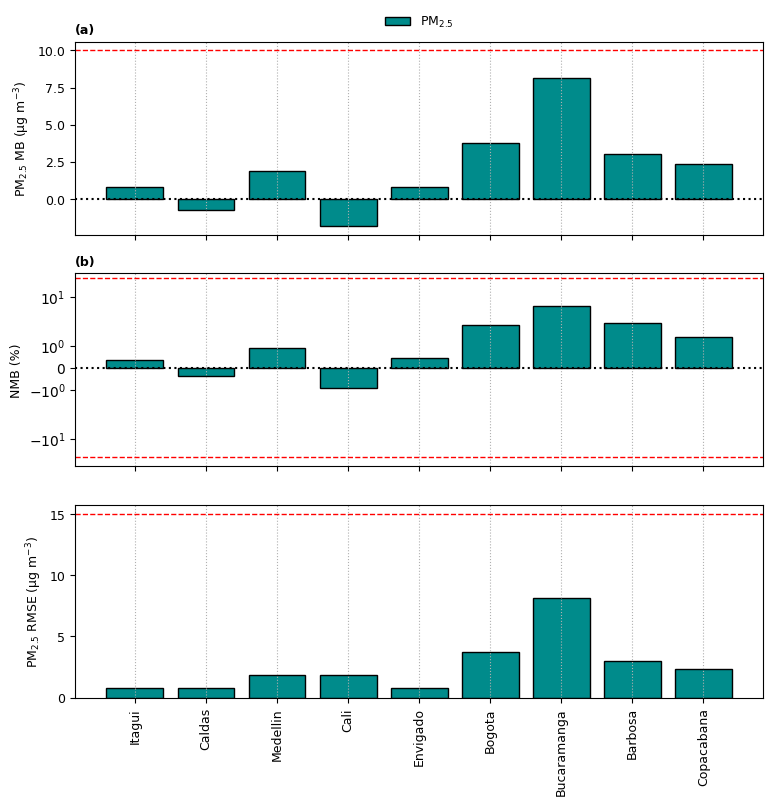

In [35]:
fig = plt.figure(figsize=(8,8))
gs = GridSpec(3,1,left = 0.09, right = 0.95, hspace=0.2, wspace=0.2, top = 0.9, bottom = 0.08)

ax = plt.subplot(gs[0])
plt.bar(np.arange(1,len(df_acag_stati.loc[0])+1), df_acag_stati.loc[0], color='darkcyan', edgecolor = 'k', label = 'PM$_{2.5}$')
plt.xticks(np.arange(1,len(df_acag_stati.loc[0])+0.01),df_acag_stati.columns, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', axis = 'x')
plt.ylabel('PM$_{2.5}$ MB (\u03bcg m$^{-3}$)', fontsize = 9)
plt.yticks(fontsize=9)
ax.xaxis.set_major_formatter(NullFormatter())
plt.title('(a)', fontweight = 'bold', fontsize = 9, loc = 'left')
plt.legend(frameon = False, bbox_to_anchor = (0.5,1.2), loc = 'upper center', fontsize = 9, ncol = 2)
plt.axhline(10, color = 'red', linestyle = '--', linewidth = 1)
plt.yticks(fontsize = 9)
plt.axhline(0, linestyle = ':', color = 'k')


ax = plt.subplot(gs[1])
plt.bar(np.arange(1,len(df_acag_stati.loc[1])+1), df_acag_stati.loc[1], color='darkcyan', edgecolor = 'k', label = 'PM$_{2.5}$')
plt.xticks(np.arange(1,len(df_acag_stati.loc[1])+0.01),df_acag_stati.columns, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', axis = 'x')
plt.ylabel('NMB (%)', fontsize = 9)
ax.xaxis.set_major_formatter(NullFormatter())
plt.axhline(30, color = 'red', linestyle = '--', linewidth = 1)
plt.axhline(-30, color = 'red', linestyle = '--', linewidth = 1)

plt.title('(b)', fontweight = 'bold', fontsize = 9, loc = 'left')
plt.yticks(np.arange(-50,50,10))
plt.yscale('symlog')
plt.axhline(0, linestyle = ':', color = 'k')

ax = plt.subplot(gs[2])
plt.bar(np.arange(1,len(df_acag_stati.loc[2])+1), df_acag_stati.loc[2], color='darkcyan', edgecolor = 'k', label = 'PM$_{2.5}$')
plt.xticks(np.arange(1,len(df_acag_stati.loc[2])+0.01),df_acag_stati.columns, rotation = 90, fontsize = 9)
plt.grid(linestyle = ':', axis = 'x')
plt.yticks(fontsize = 9)
plt.ylabel('PM$_{2.5}$ RMSE (\u03bcg m$^{-3}$)', fontsize = 9)
plt.axhline(15, color = 'red', linestyle = '--', linewidth = 1)
plt.yticks(fontsize = 9)

plt.savefig(f'{path}Figures/Errors_yearly_ACAG_stations{version}.pdf', bbox_inches = 'tight', dpi = 300)
plt.savefig(f'{path}Figures/Errors_yearly_ACAG_stations{version}.jpg', bbox_inches = 'tight', dpi = 300)
plt.show()

In [36]:
errors_mean = {}
if version == '_V6':
    errors_mean['Model'] = ['WRF-Chem', f'ACAG{version}']
else:
    errors_mean['Model'] = ['WRF-Chem', f'ACAG_V5']
errors_mean['NMB'] = [df_nmb.PM.mean(), df_acag_stati.loc[1].mean()]
errors_mean['MB'] = [df_mb.PM.mean(), df_acag_stati.loc[0].mean()]

In [37]:
data_mean = pd.DataFrame.from_dict(errors_mean)
if version == '_V6':
    data_mean.to_csv(f'{path}NMB_MB_station_mean{version}.csv', index = False)
else:
    data_mean.to_csv(f'{path}NMB_MB_station_mean_V5.csv', index = False)

In [38]:
try:
    df_v6 = pd.read_csv(f'{path}NMB_MB_station_mean_V6.csv')
    df_v5 = pd.read_csv(f'{path}NMB_MB_station_mean_V5.csv')
    df_new = pd.concat([df_v6, df_v5.loc[[1]]], ignore_index=True)
    df_new.to_csv(f'{path}NMB_MB_station_mean.csv', index = False)
except:
    print('Files not ready, run both versions')

Files not ready, run both versions
